# 28. Graph Representations

Shengli (Bruce) Jiang, University of South Carolina

## Python Packages

```python
%pip install networkx numpy matplotlib rdkit
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
NAVY = '#17233F'
RED = '#8E0B19'
PALE_BLUE = '#DCE4F1'
np.set_printoptions(precision=3, suppress=True)
plt.style.use('default')
plt.rcParams.update({
    'font.size': 11,
    'text.color': 'black',
    'axes.titlecolor': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'legend.labelcolor': 'black',
})

## Graphs

A **graph** represents relationships between objects. It is written as `G = (V, E)`, where `V` is the set of nodes and `E` is the set of edges. The meaning of an edge depends on the application.

| Application | Nodes | Edges |
| --- | --- | --- |
| Friendship network | People | Mutual friendships |
| Following network | Accounts | Directed following relationships |
| Project membership | Students and teams | Membership relationships |
| Metro network | Stations | Connections between consecutive stations |
| Airline network | Airports | Scheduled routes |
| Internet map | IP addresses | Discovered connections |
| Scene graph | Objects | Relations between objects |
| Process flow graph | Equipment | Material streams |
| Pore network | Pores | Connecting throats |
| Pixel graph | Pixels | Connections between neighboring pixels |
| Protein graph | Residues | Sequence links or spatial contacts |
| Molecular graph | Atoms | Bonds |

## Undirected Graphs

An **undirected graph** contains edges without orientation. The edge between nodes `u` and `v` is identical to the edge between `v` and `u`. Mutual friendship is an example of an undirected relationship.

In NetworkX, `nx.Graph()` creates an undirected graph.

In [3]:
import networkx as nx

G = nx.Graph()
G.add_node('Ava')
list(G.nodes)

['Ava']

The method `G.add_edge(u, v)` creates an edge between two nodes. Nodes absent from the graph are added automatically.

In [4]:
G.add_edge('Ava', 'Ben')
list(G.edges)

[('Ava', 'Ben')]

The method `G.add_edges_from()` accepts a collection of node pairs. Each pair identifies one edge.

In [5]:
G.add_edges_from([
    ('Ben', 'Cara'),
    ('Cara', 'Ava'),
    ('Cara', 'Drew'),
    ('Drew', 'Eli'),
    ('Eli', 'Faye'),
    ('Faye', 'Drew'),
])

In [6]:
print('Nodes:', G.number_of_nodes())
print('Edges:', G.number_of_edges())

Nodes: 6
Edges: 7


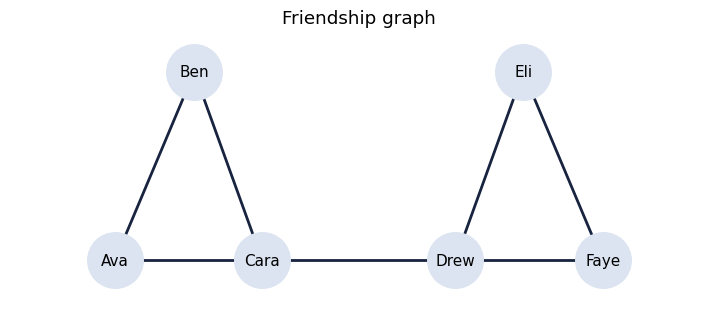

In [7]:
pos = {
    'Ava': (0, 0), 'Ben': (0.7, 1), 'Cara': (1.3, 0),
    'Drew': (3, 0), 'Eli': (3.6, 1), 'Faye': (4.3, 0),
}
fig, ax = plt.subplots(figsize=(9, 3.5))
nx.draw_networkx(
    G, pos, ax=ax, node_color=PALE_BLUE, edge_color=NAVY,
    node_size=1600, font_color='black', font_size=11, width=2,
)
ax.set_title('Friendship graph')
ax.margins(0.15)
ax.set_axis_off()
plt.show()

## Neighbors and Degree

Two nodes are **neighbors** if they share an edge.

In [8]:
sorted(G.neighbors('Cara'))

['Ava', 'Ben', 'Drew']

The **degree** of a node is the number of incident edges. Cara has degree 3 because three friendship edges meet at that node.

In [9]:
G.degree['Cara']

3

In [10]:
dict(G.degree)

{'Ava': 2, 'Ben': 2, 'Cara': 3, 'Drew': 3, 'Eli': 2, 'Faye': 2}

In an undirected graph, the sum of the node degrees equals twice the number of edges. Each edge contributes one to the degree of each endpoint.

In [11]:
print('Degree sum:', sum(dict(G.degree).values()))
print('Twice the edge count:', 2 * G.number_of_edges())

Degree sum: 14
Twice the edge count: 14


## Graph Distance

A **path** is a sequence of distinct nodes with an edge between each consecutive pair. Its length in an unweighted graph is the number of edges along the path.

The function `nx.shortest_path()` returns a path of minimum length between the specified nodes.

In [12]:
nx.shortest_path(G, 'Ava', 'Drew')

['Ava', 'Cara', 'Drew']

The **shortest-path distance** between two nodes is the minimum number of edges needed to connect them in an unweighted graph. The distance from a node to itself is 0.

In [13]:
nx.shortest_path_length(G, 'Ava', 'Drew')

2

In [14]:
hops = nx.shortest_path_length(G, source='Ava')
dict(hops)

{'Ava': 0, 'Ben': 1, 'Cara': 1, 'Drew': 2, 'Eli': 3, 'Faye': 3}

## Bridges and Components

A **connected component** is a maximal set of nodes in which every pair is connected by a path. It contains all nodes reachable from any of its members.

In [15]:
nx.number_connected_components(G)

1

A **bridge** is an edge whose removal increases the number of connected components. The Cara-Drew edge is a bridge because removing it separates the friendship graph into two components.

In [16]:
H = G.copy()
H.remove_edge('Cara', 'Drew')

In [17]:
nx.number_connected_components(H)

2

The function `nx.connected_components()` returns each connected component as a set of nodes.

In [18]:
list(nx.connected_components(H))

[{'Ava', 'Ben', 'Cara'}, {'Drew', 'Eli', 'Faye'}]

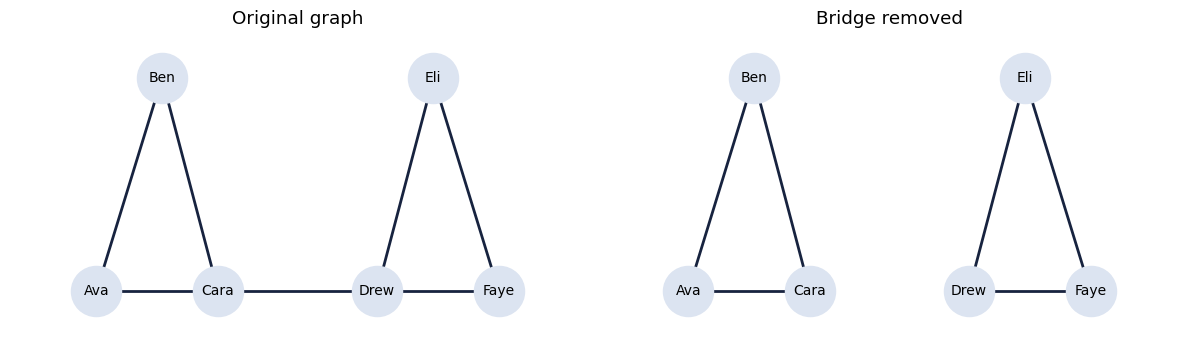

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
nx.draw_networkx(
    G, pos, ax=axes[0], node_color=PALE_BLUE, edge_color=NAVY,
    node_size=1300, font_color='black', font_size=10, width=2,
)
axes[0].set_title('Original graph')
axes[0].margins(0.15)
axes[0].set_axis_off()
nx.draw_networkx(
    H, pos, ax=axes[1], node_color=PALE_BLUE, edge_color=NAVY,
    node_size=1300, font_color='black', font_size=10, width=2,
)
axes[1].set_title('Bridge removed')
axes[1].margins(0.15)
axes[1].set_axis_off()
plt.tight_layout()
plt.show()

## Directed Graphs

A **directed graph** assigns an orientation to each edge. The ordered pair `(u, v)` represents an edge from `u` to `v`; an edge in the reverse direction is a separate relationship.

In the following network, an arrow points from the follower to the account being followed. NetworkX represents directed graphs with `nx.DiGraph()`.

In [20]:
D = nx.DiGraph()
D.add_edge('Ben', 'Ava')

In [21]:
D.add_edges_from([
    ('Cara', 'Ava'),
    ('Drew', 'Ava'),
    ('Ava', 'Ben'),
    ('Eli', 'Ben'),
    ('Faye', 'Eli'),
])

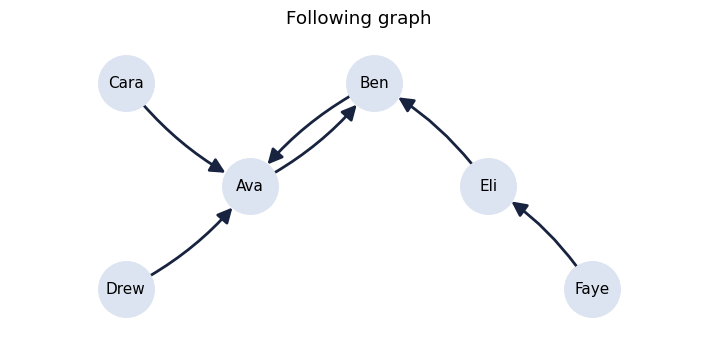

In [22]:
pos_follow = {
    'Ava': (0, 0), 'Ben': (1.2, 0.8), 'Cara': (-1.2, 0.8),
    'Drew': (-1.2, -0.8), 'Eli': (2.3, 0), 'Faye': (3.3, -0.8),
}
fig, ax = plt.subplots(figsize=(9, 4))
nx.draw_networkx(
    D, pos_follow, ax=ax, node_color=PALE_BLUE, edge_color=NAVY,
    node_size=1600, font_color='black', font_size=11, width=2,
    arrows=True, arrowsize=22, connectionstyle='arc3,rad=0.12',
)
ax.set_title('Following graph')
ax.margins(0.18)
ax.set_axis_off()
plt.show()

A **predecessor** of a node `u` is a node with a directed edge into `u`. Predecessors in the following network represent followers.

In [23]:
sorted(D.predecessors('Ava'))

['Ben', 'Cara', 'Drew']

A **successor** of a node `u` is a node reached by an outgoing edge from `u`. Successors in the following network represent the accounts that `u` follows.

In [24]:
sorted(D.successors('Ava'))

['Ben']

The **in-degree** of a node is the number of incoming edges. Its **out-degree** is the number of outgoing edges.

In [25]:
print('In-degree:', D.in_degree['Ava'])
print('Out-degree:', D.out_degree['Ava'])

In-degree: 3
Out-degree: 1


In [26]:
print('In-degree:', dict(D.in_degree))
print('Out-degree:', dict(D.out_degree))

In-degree: {'Ben': 2, 'Ava': 3, 'Cara': 0, 'Drew': 0, 'Eli': 1, 'Faye': 0}
Out-degree: {'Ben': 1, 'Ava': 1, 'Cara': 1, 'Drew': 1, 'Eli': 1, 'Faye': 1}


A **directed path** follows the orientation of every edge. The path `Faye -> Eli -> Ben` connects Faye to Ben through two directed edges.

In [27]:
nx.shortest_path(D, 'Faye', 'Ben')

['Faye', 'Eli', 'Ben']

Two nodes are **adjacent** when a direct edge connects them. A directed path can connect nonadjacent nodes, as in the Faye-Ben example.

In [28]:
D.has_edge('Faye', 'Ben')

False

## Edge Weights

An **edge weight** is a numerical value associated with an edge. In the campus graph, edge weights represent walking time in minutes.

In [29]:
R = nx.Graph()
R.add_edge('Dorm', 'Library', minutes=3)

In [30]:
R.edges['Dorm', 'Library']['minutes']

3

The method `add_weighted_edges_from()` accepts entries of the form `(u, v, w)`, where `w` is the edge weight. The argument `weight='minutes'` specifies the attribute used to store that value.

In [31]:
R.add_weighted_edges_from([
    ('Library', 'Lab', 9),
    ('Dorm', 'Cafe', 2),
    ('Cafe', 'Gate', 2),
    ('Gate', 'Lab', 3),
    ('Dorm', 'Quad', 4),
    ('Quad', 'Stadium', 2),
    ('Stadium', 'Lab', 4),
    ('Cafe', 'Quad', 3),
], weight='minutes')

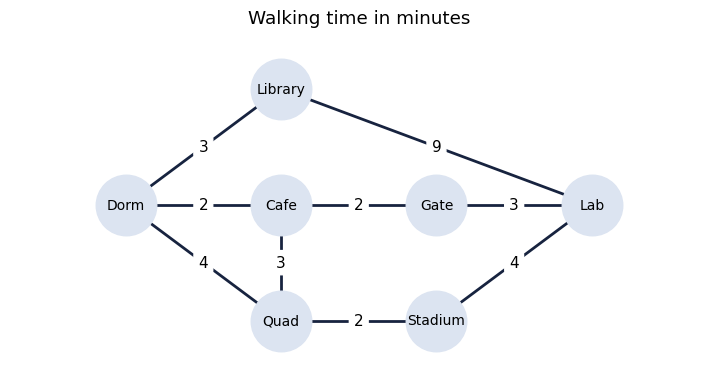

In [32]:
pos_route = {
    'Dorm': (0, 0), 'Library': (1, 1), 'Cafe': (1, 0),
    'Gate': (2, 0), 'Lab': (3, 0), 'Quad': (1, -1),
    'Stadium': (2, -1),
}
time_labels = nx.get_edge_attributes(R, 'minutes')
fig, ax = plt.subplots(figsize=(9, 4.5))
nx.draw_networkx(
    R, pos_route, ax=ax, node_color=PALE_BLUE, edge_color=NAVY,
    node_size=1900, font_color='black', font_size=10, width=2,
)
nx.draw_networkx_edge_labels(
    R, pos_route, edge_labels=time_labels, ax=ax,
    font_color='black', font_size=11, rotate=False,
)
ax.set_title('Walking time in minutes')
ax.margins(0.18)
ax.set_axis_off()
plt.show()

## Weighted Shortest Paths

A **weighted shortest path** minimizes the sum of the edge weights along the path. Without a `weight` argument, `nx.shortest_path()` assigns equal cost to every edge and minimizes the number of edges.

In [33]:
fewest_edges = nx.shortest_path(R, 'Dorm', 'Lab')
print(fewest_edges)
print('Edges:', len(fewest_edges) - 1)

['Dorm', 'Library', 'Lab']
Edges: 2


The function `nx.path_weight(G, path, weight)` returns the sum of the specified edge attribute along a given path.

In [34]:
nx.path_weight(R, fewest_edges, 'minutes')

12

With `weight='minutes'`, total walking time determines the path cost. The fastest route in the campus graph contains 3 edges and takes 7 minutes.

In [35]:
fastest = nx.shortest_path(R, 'Dorm', 'Lab', weight='minutes')
print(fastest)
print('Edges:', len(fastest) - 1)

['Dorm', 'Cafe', 'Gate', 'Lab']
Edges: 3


In [36]:
nx.path_weight(R, fastest, 'minutes')

7

## Routing After Edge Removal

An edge closure is represented by removing the corresponding edge. After the Gate-Lab connection closes, the fastest Dorm-Lab route passes through Quad and Stadium, with a total time of 10 minutes.

In [37]:
closed = R.copy()
closed.remove_edge('Gate', 'Lab')

In [38]:
detour = nx.shortest_path(closed, 'Dorm', 'Lab', weight='minutes')
print(detour)

['Dorm', 'Quad', 'Stadium', 'Lab']


In [39]:
nx.path_weight(closed, detour, 'minutes')

10

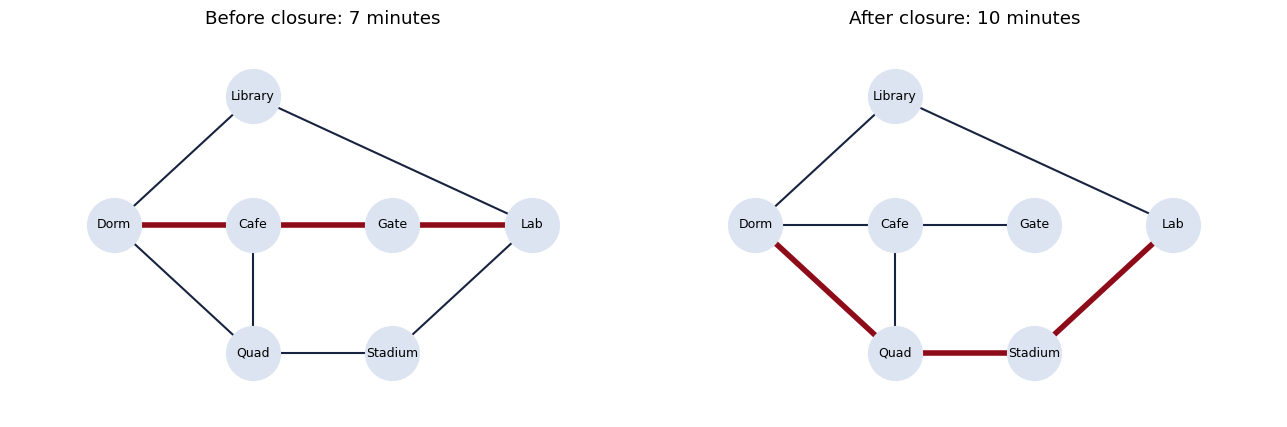

In [40]:
fastest_edges = list(zip(fastest[:-1], fastest[1:]))
detour_edges = list(zip(detour[:-1], detour[1:]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
nx.draw_networkx(
    R, pos_route, ax=axes[0], node_color=PALE_BLUE, edge_color=NAVY,
    node_size=1500, font_color='black', font_size=9, width=1.5,
)
nx.draw_networkx_edges(
    R, pos_route, edgelist=fastest_edges, ax=axes[0],
    edge_color=RED, width=4, node_size=1500,
)
axes[0].set_title('Before closure: 7 minutes')
axes[0].margins(0.18)
axes[0].set_axis_off()
nx.draw_networkx(
    closed, pos_route, ax=axes[1], node_color=PALE_BLUE, edge_color=NAVY,
    node_size=1500, font_color='black', font_size=9, width=1.5,
)
nx.draw_networkx_edges(
    closed, pos_route, edgelist=detour_edges, ax=axes[1],
    edge_color=RED, width=4, node_size=1500,
)
axes[1].set_title('After closure: 10 minutes')
axes[1].margins(0.18)
axes[1].set_axis_off()
plt.tight_layout()
plt.show()

## Molecular Graphs

A **molecular graph** represents atoms as nodes and bonds as edges. **Heavy atoms** are atoms other than hydrogen. Ethanol's heavy-atom graph contains 3 nodes and 2 edges, with hydrogen atoms represented implicitly.

In [41]:
from rdkit import Chem

mol = Chem.MolFromSmiles('CCO')

RDKit assigns zero-based indices to atoms. For ethanol read from `CCO`, indices 0 and 1 identify the carbon atoms; index 2 identifies oxygen.

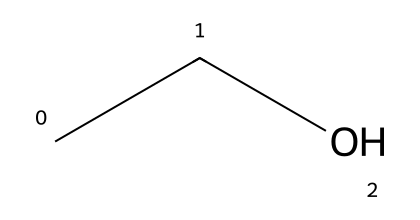

In [42]:
from rdkit.Chem import Draw

draw_options = Draw.MolDrawOptions()
draw_options.useBWAtomPalette()
draw_options.addAtomIndices = True
Draw.MolToImage(mol, size=(420, 220), options=draw_options)

In [43]:
atom = mol.GetAtomWithIdx(0)
atom.GetSymbol()

'C'

The atom degree returned by `GetDegree()` counts directly bonded atoms present in the molecular graph. Implicit hydrogens are excluded from this count.

In [44]:
print('Implicit H:', atom.GetNumImplicitHs())
print('Degree:', atom.GetDegree())

Implicit H: 3
Degree: 1


In [45]:
bond = mol.GetBondWithIdx(0)
bond.GetBondType()

rdkit.Chem.rdchem.BondType.SINGLE

In [46]:
print('Begin atom index:', bond.GetBeginAtomIdx())
print('End atom index:', bond.GetEndAtomIdx())

Begin atom index: 0
End atom index: 1


The labels `C0` and `C1` identify the carbon nodes; `O2` identifies the oxygen node. The numerical part of each label is the RDKit atom index.

In [47]:
atom_order = ['C0', 'C1', 'O2']
M = nx.Graph()
for atom in mol.GetAtoms():
    name = atom_order[atom.GetIdx()]
    M.add_node(
        name,
        element=atom.GetSymbol(),
        implicit_h=atom.GetNumImplicitHs(),
    )

In [48]:
for bond in mol.GetBonds():
    first = atom_order[bond.GetBeginAtomIdx()]
    second = atom_order[bond.GetEndAtomIdx()]
    M.add_edge(first, second, bond_type=str(bond.GetBondType()).title())

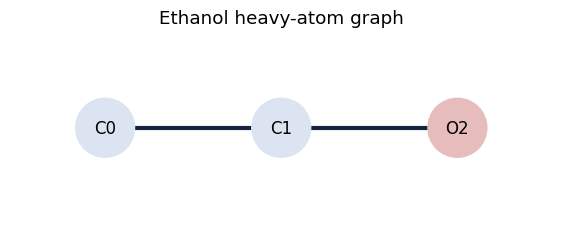

In [49]:
pos_molecule = {'C0': (0, 0), 'C1': (1, 0), 'O2': (2, 0)}
fig, ax = plt.subplots(figsize=(7, 2.5))
nx.draw_networkx(
    M, pos_molecule, ax=ax,
    node_color=[PALE_BLUE, PALE_BLUE, '#E6BCBD'],
    node_size=1800, font_color='black', font_size=12,
    edge_color=NAVY, width=3,
)
ax.set_title('Ethanol heavy-atom graph')
ax.margins(0.2)
ax.set_axis_off()
plt.show()

### Node Attributes

A **node attribute** describes a property of an individual node. The element symbol identifies the atom type. The implicit hydrogen count records attached hydrogens omitted as nodes from ethanol's heavy-atom graph.

In [50]:
print('Node  Element  Implicit H  Degree')
for node in atom_order:
    attributes = M.nodes[node]
    print(
        f"{node:<5} {attributes['element']:<8} "
        f"{attributes['implicit_h']:<11} {M.degree[node]}"
    )

Node  Element  Implicit H  Degree
C0    C        3           1
C1    C        2           2
O2    O        1           1


### Edge Attributes

An **edge attribute** describes a property of an individual connection. In a molecular graph, bond type is an edge attribute. Both heavy-atom bonds in ethanol are single bonds.

In [51]:
print('Edge    Bond type')
for first, second, attributes in M.edges(data=True):
    print(f"{first}-{second}   {attributes['bond_type']}")

Edge    Bond type
C0-C1   Single
C1-O2   Single


### Adjacency Matrix

An **adjacency matrix** records which nodes are connected. For a graph with `N` nodes, it has `N` rows and `N` columns. A binary entry `A[i, j]` is 1 when nodes `i` and `j` share an edge, and 0 otherwise.

Rows and columns use the same node order, specified by `atom_order` in the ethanol example.

In [52]:
A = nx.to_numpy_array(M, nodelist=atom_order, weight=None, dtype=int)
print('Node order:', atom_order)
print(A)

Node order: ['C0', 'C1', 'O2']
[[0 1 0]
 [1 0 1]
 [0 1 0]]


For an undirected graph, `A[i, j] = A[j, i]`, so the adjacency matrix is symmetric. The diagonal entries are zero when the graph contains no self-loops.

### Explicit Hydrogens

In an **explicit hydrogen representation**, hydrogen atoms appear as nodes with bonds to their neighboring atoms. Ethanol then contains 9 nodes and 8 edges. The function `Chem.AddHs()` constructs this representation from the molecule with implicit hydrogens.

In [53]:
mol_with_h = Chem.AddHs(mol)
print('Heavy-atom graph:', mol.GetNumAtoms(), 'nodes,', mol.GetNumBonds(), 'edges')
print('Explicit hydrogen graph:', mol_with_h.GetNumAtoms(), 'nodes,', mol_with_h.GetNumBonds(), 'edges')

Heavy-atom graph: 3 nodes, 2 edges
Explicit hydrogen graph: 9 nodes, 8 edges


### Graph-Level Attributes

A **graph-level attribute** describes the entire graph. For a molecule, molar mass is a graph-level descriptor with units of g/mol. RDKit calculates it with `Descriptors.MolWt()`.

In [54]:
from rdkit.Chem import Descriptors

M.graph['molecular_weight_g_per_mol'] = Descriptors.MolWt(mol)
M.graph

{'molecular_weight_g_per_mol': 46.069}